# 01 Data inventory
Loads every raw dataset that exists in `data/raw/` and reports size, columns, coordinate system, and obvious problems. Nothing is cleaned or merged here.

In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("..") / "data" / "raw"
OUT = Path("..") / "outputs"

def inventory_spatial(path):
    """Print row count, columns, CRS, empty/invalid geometries and duplicate rows for a spatial file."""
    gdf = gpd.read_file(path)
    print(f"--- {path}")
    print("rows:", len(gdf), "| CRS:", gdf.crs)
    print("columns:", list(gdf.columns))
    print("empty geometries:", int(gdf.geometry.is_empty.sum()), "| invalid geometries:", int((~gdf.geometry.is_valid).sum()))
    print("missing values per column (non-zero only):")
    print(gdf.drop(columns="geometry").isna().sum().loc[lambda s: s > 0].to_string() or "  none")
    print("duplicate attribute rows:", int(gdf.drop(columns="geometry").duplicated().sum()))
    return gdf


## CAL FIRE Fire Hazard Severity Zones

In [2]:
sra = inventory_spatial(RAW / "fhsz" / "fhsz_sra_2023map.geojson")
lra = inventory_spatial(RAW / "fhsz" / "fhsz_lra_2025map.geojson")
print(sra["FHSZ_Description"].value_counts().to_string())
print(lra["FHSZ_Description"].value_counts().to_string())

--- ..\data\raw\fhsz\fhsz_sra_2023map.geojson
rows: 2066 | CRS: EPSG:4326
columns: ['OBJECTID', 'SRA', 'FHSZ', 'FHSZ_Description', 'Shape__Area', 'Shape__Length', 'geometry']


empty geometries: 0 | invalid geometries: 32
missing values per column (non-zero only):
Series([], )
duplicate attribute rows: 0


--- ..\data\raw\fhsz\fhsz_lra_2025map.geojson
rows: 385 | CRS: EPSG:4326
columns: ['OBJECTID', 'SRA', 'FHSZ', 'FHSZ_Description', 'Shape__Area', 'Shape__Length', 'geometry']


empty geometries: 0 | invalid geometries: 5
missing values per column (non-zero only):
Series([], )
duplicate attribute rows: 0
FHSZ_Description
Very High    1386
High          454
Moderate      226
FHSZ_Description
Moderate       146
High           115
Very High       68
NonWildland     56


## Pre-2018 FHSZ maps
Downloaded by `src/01b_download_fhsz_pre2018.py`. Skipped with a message if absent.

In [3]:
pre = RAW / "fhsz_pre2018"
files = list(pre.rglob("*.shp")) + list(pre.rglob("*.zip")) if pre.exists() else []
print(f"{len(files)} pre-2018 files found" if files else "NOT DOWNLOADED: run src/01b_download_fhsz_pre2018.py")
for f in files:
    print(f.name)

7 pre-2018 files found
butte_fhszl06_1.4sn_wayback20161223.zip
butte_fhszl06_3.4ns_wayback20161223.zip
fhszs.sn_wayback20161223.zip
shasta_fhszl06_1.45sn_wayback20161223.zip
shasta_fhszl06_3.45ns_wayback20161223.zip
tehama_fhszl06_1.52sn_wayback20161223.zip
tehama_fhszl06_3.52ns_wayback20161223.zip


## Camp Fire perimeter

In [4]:
camp = inventory_spatial(RAW / "camp_fire" / "camp_fire_2018.geojson")
camp[["FIRE_NAME", "UNIT_ID", "ALARM_DATE", "CONT_DATE", "GIS_ACRES"]]

--- ..\data\raw\camp_fire\camp_fire_2018.geojson
rows: 1 | CRS: EPSG:4326
columns: ['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'INC_NUM', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD', 'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NAME', 'FIRE_NUM', 'Shape__Area', 'Shape__Length', 'geometry']
empty geometries: 0 | invalid geometries: 0
missing values per column (non-zero only):
COMMENTS        1
COMPLEX_NAME    1
FIRE_NUM        1
duplicate attribute rows: 0


,FIRE_NAME,UNIT_ID,ALARM_DATE,CONT_DATE,GIS_ACRES
0,CAMP,BTU,1541635200000,1543190400000,153335.6


## Census tracts (TIGER/Line)

In [5]:
t = inventory_spatial(next((RAW / "census" / "tiger_2018_ca_tracts").glob("*.shp")))
tracts = t[t["COUNTYFP"].isin(["007", "089", "103"])]
print("study-area tracts:", len(tracts))

--- ..\data\raw\census\tiger_2018_ca_tracts\tl_2018_06_tract.shp
rows: 8057 | CRS: EPSG:4269
columns: ['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry']


empty geometries: 0 | invalid geometries: 0
missing values per column (non-zero only):
Series([], )
duplicate attribute rows: 0
study-area tracts: 110


## ACS 5-year tables
Downloaded by `src/04_download_acs.py`. Skipped with a message if the CSV is not there yet.

In [6]:
f = RAW / "census" / "acs5_2018_tracts.csv"
if not f.exists():
    print(f"{f.name}: NOT DOWNLOADED (run src/04_download_acs.py)")
else:
    acs = pd.read_csv(f, dtype={"GEOID": str})
    print(f"--- {f.name}: rows {len(acs)}, columns {list(acs.columns)}")
    print("tracts with no income estimate:", int(acs["median_hh_income"].isna().sum()))
    print("duplicate GEOID:", int(acs["GEOID"].duplicated().sum()))
    print("tracts in ACS but not TIGER:", len(set(acs["GEOID"]) - set(tracts["GEOID"])), "| in TIGER but not ACS:", len(set(tracts["GEOID"]) - set(acs["GEOID"])))

--- acs5_2018_tracts.csv: rows 110, columns ['GEOID', 'median_hh_income', 'total_pop', 'county']
tracts with no income estimate: 0
duplicate GEOID: 0
tracts in ACS but not TIGER: 0 | in TIGER but not ACS: 0


## Home sales
No sales data has been acquired yet.

In [7]:
sales_files = [p for p in (RAW / "sales").glob("*")] if (RAW / "sales").exists() else []
if not sales_files:
    print("NO SALES DATA in data/raw/sales/. Coverage: 0 rows.")
else:
    print(sales_files)  # add row count, sale-date range, duplicates checks here once a source is chosen

NO SALES DATA in data/raw/sales/. Coverage: 0 rows.


## Map: FHSZ with Camp Fire perimeter

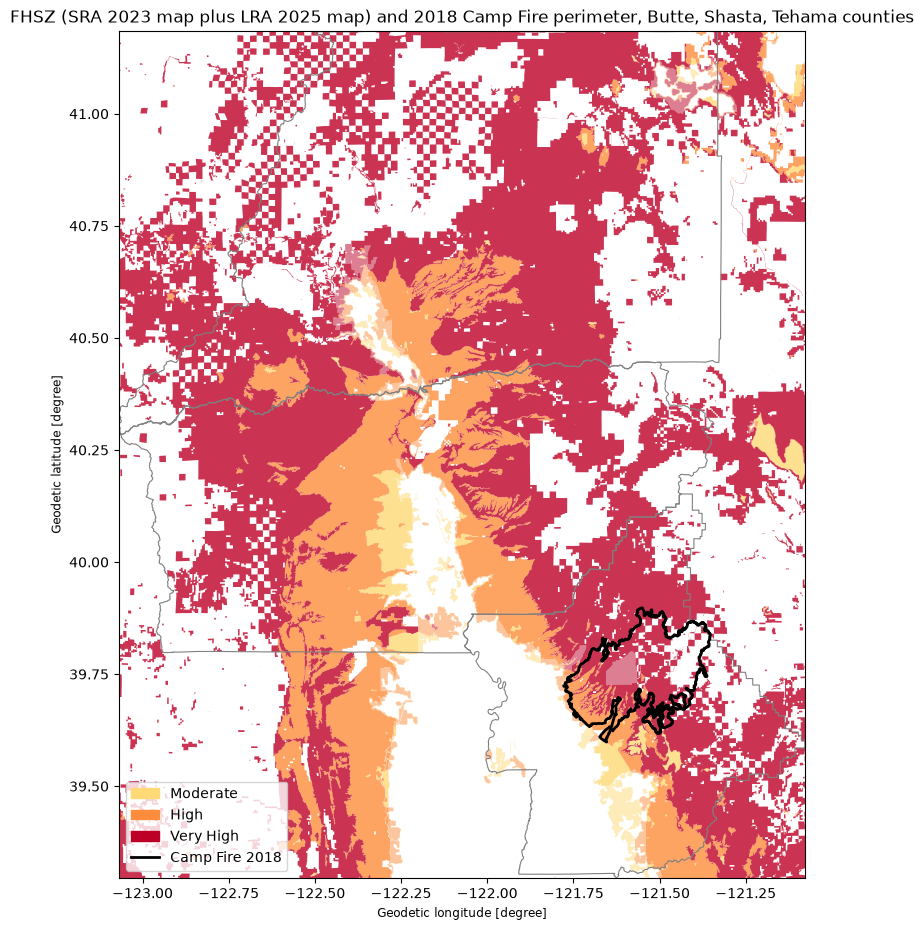

In [8]:
fig, ax = plt.subplots(figsize=(9, 11))
counties = tracts.dissolve(by="COUNTYFP")
counties.boundary.plot(ax=ax, color="grey", linewidth=0.8)
colors = {"Moderate": "#fed976", "High": "#fd8d3c", "Very High": "#bd0026"}
for layer, label in ((sra, "SRA (2023 map)"), (lra, "LRA (2025 map)")):
    for zone, c in colors.items():
        sub = layer[layer["FHSZ_Description"] == zone]
        if len(sub):
            sub.plot(ax=ax, color=c, alpha=0.8 if label.startswith("SRA") else 0.5, linewidth=0)
camp.boundary.plot(ax=ax, color="black", linewidth=2)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(color=c, label=z) for z, c in colors.items()] + [Line2D([0], [0], color="black", lw=2, label="Camp Fire 2018")], loc="lower left")
minx, miny, maxx, maxy = counties.total_bounds
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
ax.set_title("FHSZ (SRA 2023 map plus LRA 2025 map) and 2018 Camp Fire perimeter, Butte, Shasta, Tehama counties")
OUT.mkdir(exist_ok=True)
fig.savefig(OUT / "fhsz_camp_fire_map.png", dpi=150, bbox_inches="tight")